# ¿Cuántas piezas puede colocar una IA dentro del sitio activo de una enzima?

**En 41 tareas de prueba, RFdiffusion3 acierta el motivo atómico en el 37,7 % de los intentos; la versión anterior, en el 23,5 %. Y donde el sitio activo tiene cinco o más grupos de residuos — el caso difícil — la ventaja pasa de 1,50× a 3,67×.** Después, con 96 diseños y sin una sola ronda de evolución dirigida, salieron enzimas que funcionan en el tubo de ensayo.

**Paper:** Butcher et al. (2026). *Atomic functional site scaffolding in biopolymers with RFdiffusion3*. **Science**.
**DOI:** [10.1126/science.aeh2982](https://doi.org/10.1126/science.aeh2982)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ciencia-a-Mordiscos/lab/blob/main/papers/2026-11-27-rfdiffusion3-sitios-activos-atomicos/notebook.ipynb)

**Video:** Pendiente

Una enzima trabaja con un puñado de átomos. El resto de la proteína — cientos de aminoácidos — está ahí para sostener esos átomos en la posición exacta, con la orientación exacta. Diseñar una enzima desde cero es, sobre todo, ese problema de sujeción: te dan el sitio activo (el **motivo**) y tienes que inventar la proteína que lo aguanta.

RFdiffusion3 (RFD3) es la herramienta de IA generativa que el equipo de David Baker presenta para eso. La novedad que ellos destacan es que trabaja con **átomos libres**: en vez de pedirle un fragmento de proteína con su esqueleto completo, le pides átomos sueltos en coordenadas concretas — un metal aquí, este oxígeno a esta distancia — y que construya alrededor.

Vamos a abrir los datos que el paper publica bajo su mismo DOI (el **Data S1** de las figuras y las tablas del material suplementario) y a mirar tres cosas:

1. El **benchmark AME**: 41 tareas de sujeción de motivos atómicos, 100 esqueletos generados por tarea. Una tarea cuenta como acierto si al menos una de las 8 secuencias propuestas reconstruye el motivo con un error menor a 1,5 Å y sin choques con el ligando.
2. El **tiempo** que tarda cada método en producir un diseño.
3. Lo que pasó en el banco de laboratorio: **ZAPP-1**, una fosfotriesterasa diseñada desde cero, y las proteasas de zinc contra la transtiretina.

⚠️ **Dos avisos antes de empezar.** Las tasas de éxito de RFdiffusion1 y RFdiffusion2 son las que los autores midieron en su propio benchmark: aquí comparamos números publicados, no una reevaluación independiente. Y ninguno de estos experimentos pasa por un ser vivo más complejo que una bacteria: las proteínas se expresan en *E. coli* y se miden en el tubo.

In [1]:
# ══════════════════════════════════════════════════════════════
# Configuración — modifica estos valores para explorar
# ══════════════════════════════════════════════════════════════
UMBRAL_A = 1.25            # umbral de error del motivo en AME-2 (Å); el paper usa 1,25
CORTE_ISLAS = 5            # a partir de cuántas islas de residuos empieza el caso difícil
TEOZIMA = 'phosphotriesterase'   # aldolase, decarboxylase, glycosidase o phosphotriesterase
FUENTE = 'Fuente: Butcher et al. (2026), Science | Datos: Data S1 y Supplementary Materials del mismo DOI'
COLOR_DATOS = '#2563EB'
COLOR_ALERTA = '#DC2626'
COLOR_REFERENCIA = '#D97706'
COLOR_SEC = '#059669'
COLOR_VIOLETA = '#7C3AED'
COLOR_GRIS = '#BBBBBB'

import os, re, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy import stats

BASE = 'https://raw.githubusercontent.com/Ciencia-a-Mordiscos/lab/main/papers/2026-11-27-rfdiffusion3-sitios-activos-atomicos'
ARCHIVOS = ['ame_pass_rate_por_tarea.csv', 'velocidad_inferencia.csv', 'ame2_resumen_por_tarea.csv',
            'ame2_rmsd_histograma.csv', 'zapp1_knockouts.csv', 'zapp1_michaelis_menten.csv',
            'zapp1_mm_fit.csv', 'proteasas_mm_fit.csv']
os.makedirs('datos', exist_ok=True)
os.makedirs('figuras', exist_ok=True)
for a in ARCHIVOS:
    if not os.path.exists(f'datos/{a}'):
        urllib.request.urlretrieve(f'{BASE}/datos/{a}', f'datos/{a}')

style_file = '../../cam.mplstyle'
if not os.path.exists(style_file):
    style_file = '/tmp/cam.mplstyle'
    if not os.path.exists(style_file):
        urllib.request.urlretrieve('https://raw.githubusercontent.com/Ciencia-a-Mordiscos/lab/main/cam.mplstyle', style_file)
plt.style.use(style_file)

# Números en formato español: coma decimal, punto de miles, signo menos tipográfico
def es(x):
    s = str(x)
    s = re.sub(r'(\d)[eE]\+?(-?)0*(\d+)', r'\1×10^\2\3', s)
    s = re.sub(r'(?<=\d),(?=\d{3}(?!\d))', '_', s)
    s = re.sub(r'(?<=\d)\.(?=\d)', ',', s)
    s = re.sub(r'(?<![\w,])-(?=\d)', '−', s)
    return s.replace('_', '.')

def pr(*a):
    print(*[es(x) for x in a])

COMA = FuncFormatter(lambda v, _: es(f'{v:g}'))

# ── carga
ame = pd.read_csv('datos/ame_pass_rate_por_tarea.csv')
vel = pd.read_csv('datos/velocidad_inferencia.csv')
ame2 = pd.read_csv('datos/ame2_resumen_por_tarea.csv')
hist = pd.read_csv('datos/ame2_rmsd_histograma.csv')
ko = pd.read_csv('datos/zapp1_knockouts.csv')
mm = pd.read_csv('datos/zapp1_michaelis_menten.csv')
fit = pd.read_csv('datos/zapp1_mm_fit.csv')
prot = pd.read_csv('datos/proteasas_mm_fit.csv')

METODOS = [('rfd3', 'RFdiffusion3', COLOR_DATOS), ('rfd2', 'RFdiffusion2', COLOR_ALERTA),
           ('rfd1', 'RFdiffusion1', COLOR_GRIS)]
# las cuatro teozimas de AME-2, con su nombre en español
NOMBRES = {'aldolase': 'aldolasa', 'decarboxylase': 'descarboxilasa',
           'glycosidase': 'glicosidasa', 'phosphotriesterase': 'fosfotriesterasa'}

pr(f'AME: {len(ame)} tareas, {ame.n_backbones.iloc[0]} esqueletos por tarea, '
   f'islas de residuos de {ame.islas_residuos.min()} a {ame.islas_residuos.max()}')
for m, nombre, _ in METODOS:
    v = ame[f'{m}_pass_rate'] * 100
    pr(f'  {nombre:<14} media {v.mean():5.1f} %  mediana {v.median():5.1f} %  '
       f'IQR {v.quantile(.25):4.0f}–{v.quantile(.75):4.0f} %  tareas con 0 aciertos: {(v == 0).sum()}/{len(v)}')

# Diseño pareado: las mismas 41 tareas para los tres métodos → Wilcoxon y d pareado (no Mann-Whitney)
dif = ame.rfd3_pass_rate - ame.rfd2_pass_rate
w = stats.wilcoxon(ame.rfd3_pass_rate, ame.rfd2_pass_rate)
pr(f'RFD3 − RFD2: diferencia media {dif.mean()*100:.1f} pp, mediana {dif.median()*100:.1f} pp | '
   f'gana en {(dif > 0).sum()}/{len(dif)} tareas ({(dif == 0).sum()} empates, {(dif < 0).sum()} derrotas)')
pr(f'  Wilcoxon pareado p = {w.pvalue:.2g} | d pareado = {dif.mean()/dif.std(ddof=1):.2f} (grande)')

grupos = {'1–4 islas': ame[ame.islas_residuos < CORTE_ISLAS],
          f'{CORTE_ISLAS}–7 islas': ame[ame.islas_residuos >= CORTE_ISLAS]}
for nombre, sub in grupos.items():
    a3, a2 = sub.rfd3_pass_rate.mean()*100, sub.rfd2_pass_rate.mean()*100
    pr(f'{nombre:<10} (n = {len(sub)} tareas): RFD3 {a3:.1f} %  vs RFD2 {a2:.1f} %  →  {a3/a2:.2f}×')
for m, nombre, _ in METODOS[:2]:
    rho = stats.spearmanr(ame.islas_residuos, ame[f'{m}_pass_rate'])
    pr(f'  más islas, menos aciertos ({nombre}): Spearman ρ = {rho.statistic:.2f} (p = {rho.pvalue:.1g})')

tot = hist.groupby('metodo').n_disenos.sum()
pr(f'AME-2: {hist.n_disenos.sum():_} diseños en total, {tot.iloc[0]:_} por método, '
   f'4 teozimas × {int(ame2.n_disenos.iloc[0]):_} diseños')
pr(f'ZAPP-1: kcat/Km = {fit.kcat_km_M1s1.iloc[0]:.2f} ± {fit.kcat_km_err.iloc[0]:.2f} M⁻¹ s⁻¹ '
   f'(kcat {fit.kcat_s1.iloc[0]:.4f} s⁻¹, Km {fit.Km_uM.iloc[0]/1000:.1f} mM, R² = {fit.R2.iloc[0]:.3f})')

AME: 41 tareas, 100 esqueletos por tarea, islas de residuos de 1 a 7
  RFdiffusion3   media  37,7 %  mediana  35,0 %  IQR   18–  58 %  tareas con 0 aciertos: 0/41
  RFdiffusion2   media  23,5 %  mediana  14,0 %  IQR    6–  36 %  tareas con 0 aciertos: 0/41
  RFdiffusion1   media   5,1 %  mediana   0,0 %  IQR    0–   1 %  tareas con 0 aciertos: 26/41
RFD3 − RFD2: diferencia media 14,2 pp, mediana 15,0 pp | gana en 37/41 tareas (2 empates, 2 derrotas)
  Wilcoxon pareado p = 1,7×10^−7 | d pareado = 1,28 (grande)
1–4 islas  (n = 29 tareas): RFD3 47,2 %  vs RFD2 31,6 %  →  1,50×
5–7 islas  (n = 12 tareas): RFD3 14,7 %  vs RFD2 4,0 %  →  3,67×
  más islas, menos aciertos (RFdiffusion3): Spearman ρ = −0,77 (p = 5×10^−9)
  más islas, menos aciertos (RFdiffusion2): Spearman ρ = −0,85 (p = 3×10^−12)
AME-2: 128.000 diseños en total, 64.000 por método, 4 teozimas × 16.000 diseños
ZAPP-1: kcat/Km = 1,97 ± 0,53 M⁻¹ s⁻¹ (kcat 0,0153 s⁻¹, Km 7,8 mM, R² = 0,990)


Empecemos por el benchmark. Aquí está.

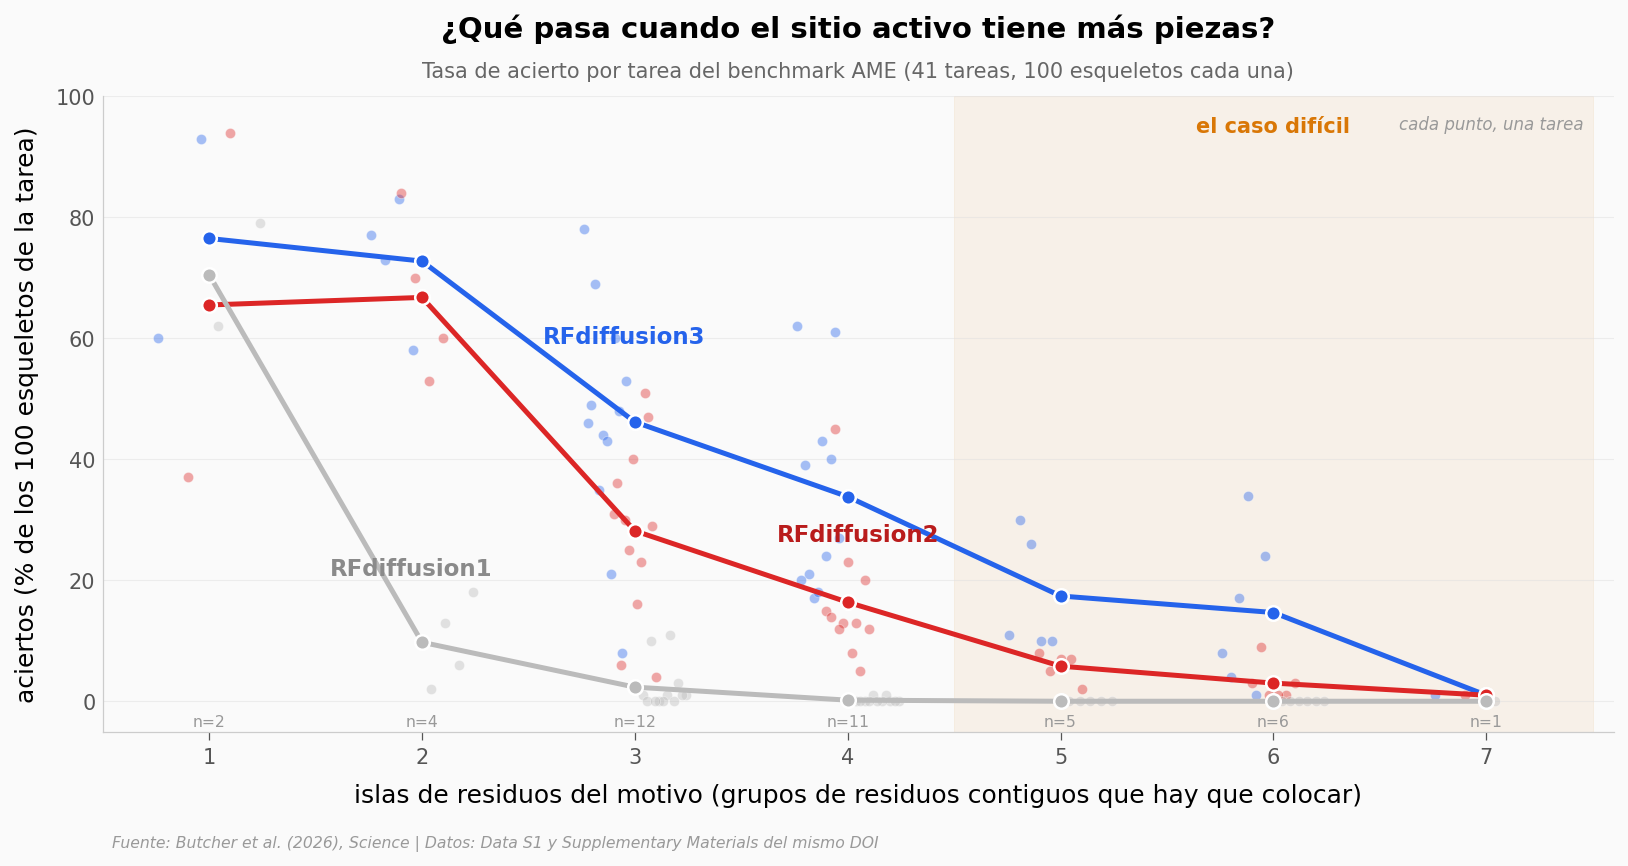

1 isla(s), n =  2:  RFD3  76,5 %   RFD2  65,5 %   RFD1  70,5 %
2 isla(s), n =  4:  RFD3  72,8 %   RFD2  66,8 %   RFD1   9,8 %
3 isla(s), n = 12:  RFD3  46,2 %   RFD2  28,2 %   RFD1   2,3 %
4 isla(s), n = 11:  RFD3  33,8 %   RFD2  16,4 %   RFD1   0,2 %
5 isla(s), n =  5:  RFD3  17,4 %   RFD2   5,8 %   RFD1   0,0 %
6 isla(s), n =  6:  RFD3  14,7 %   RFD2   3,0 %   RFD1   0,0 %
7 isla(s), n =  1:  RFD3   1,0 %   RFD2   1,0 %   RFD1   0,0 %
tarea con más islas (M0375_4ts9, 7 islas): RFD3 1 %, RFD2 1 %, RFD1 0 %
choques con el ligando en RFD3: media 3,0 %, máximo 20 % en una tarea


In [2]:
fig, ax = plt.subplots(figsize=(13, 5.5))
np.random.seed(42)

medias = {}
desplaz = {'rfd3': -0.14, 'rfd2': 0.0, 'rfd1': 0.14}
for m, nombre, color in METODOS:
    # una tarea = un punto; jitter reproducible dentro de su grupo de islas
    for isla, sub in ame.groupby('islas_residuos'):
        n = len(sub)
        xs = np.linspace(isla - 0.10, isla + 0.10, n) + desplaz[m]
        np.random.shuffle(xs)
        ax.scatter(xs, sub[f'{m}_pass_rate'] * 100, color=color, s=24, alpha=0.40,
                   edgecolors='white', linewidths=0.4, zorder=4)
    g = ame.groupby('islas_residuos')[f'{m}_pass_rate'].mean() * 100
    medias[m] = g
    ax.plot(g.index, g.values, color=color, lw=2.4, marker='o', ms=7,
            markeredgecolor='white', markeredgewidth=1.2, zorder=6)

# etiquetas inline en islas donde las tres curvas están separadas
ax.text(2.95, medias['rfd3'].loc[3] + 13, 'RFdiffusion3', color=COLOR_DATOS,
        fontsize=11, fontweight='bold', ha='center', zorder=7)
ax.text(4.05, medias['rfd2'].loc[4] + 10, 'RFdiffusion2', color='#B91C1C',
        fontsize=11, fontweight='bold', ha='center', zorder=7)
ax.text(1.95, medias['rfd1'].loc[2] + 11, 'RFdiffusion1', color='#8A8A8A',
        fontsize=11, fontweight='bold', ha='center', zorder=7)

# el caso difícil, sombreado
ax.axvspan(CORTE_ISLAS - 0.5, 7.5, color=COLOR_REFERENCIA, alpha=0.07, zorder=1)
ax.text((CORTE_ISLAS + 7.5) / 2 - 0.25, 94, 'el caso difícil', color=COLOR_REFERENCIA,
        fontsize=10, fontweight='bold', ha='center')

ax.set_title('¿Qué pasa cuando el sitio activo tiene más piezas?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, 'Tasa de acierto por tarea del benchmark AME (41 tareas, 100 esqueletos cada una)',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
ax.set_xlabel('islas de residuos del motivo (grupos de residuos contiguos que hay que colocar)')
ax.set_ylabel('aciertos (% de los 100 esqueletos de la tarea)')
ax.set_xticks(range(1, 8))
ax.set_ylim(-5, 100)
ax.set_xlim(0.5, 7.6)
for isla, sub in ame.groupby('islas_residuos'):
    ax.text(isla, -4.2, f'n={len(sub)}', fontsize=7.5, color='#999999', ha='center')
ax.text(0.98, 0.97, 'cada punto, una tarea', transform=ax.transAxes, fontsize=8,
        color='#999999', ha='right', va='top', style='italic')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/ame_pass_rate_vs_islas.png', dpi=200, bbox_inches='tight')
plt.show()

for isla in sorted(ame.islas_residuos.unique()):
    s = ame[ame.islas_residuos == isla]
    pr(f'{isla} isla(s), n = {len(s):2d}:  RFD3 {s.rfd3_pass_rate.mean()*100:5.1f} %   '
       f'RFD2 {s.rfd2_pass_rate.mean()*100:5.1f} %   RFD1 {s.rfd1_pass_rate.mean()*100:5.1f} %')
peor = ame.loc[ame.islas_residuos.idxmax()]
# print() y no pr() en esta línea: el identificador de la tarea lleva guion bajo y es() lo tocaría
print(f'tarea con más islas ({peor.tarea}, {peor.islas_residuos} islas): '
      f'RFD3 {peor.rfd3_pass_rate*100:.0f} %, RFD2 {peor.rfd2_pass_rate*100:.0f} %, '
      f'RFD1 {peor.rfd1_pass_rate*100:.0f} %')
pr(f'choques con el ligando en RFD3: media {ame.rfd3_ligand_clash_rate.mean()*100:.1f} %, '
   f'máximo {ame.rfd3_ligand_clash_rate.max()*100:.0f} % en una tarea')

Lo primero que salta: la dificultad no es una opinión. Cuantas más islas de residuos hay que colocar, menos aciertan **todos** los métodos (Spearman ρ = −0,77 para RFD3; ρ = −0,85 para RFD2). Nadie se escapa de la pendiente.

Lo segundo es dónde se abre la distancia. Con pocas piezas, los dos métodos recientes andan cerca: 47,2 % frente a 31,6 %, un factor 1,50×. En el tramo sombreado — cinco islas o más, 12 tareas — la cosa se separa: 14,7 % frente a 4,0 %, un factor 3,67×. Es exactamente donde el paper pone el acento («sitios que exigen colocar con precisión los átomos de más de cuatro residuos catalíticos»), aunque conviene ser literal: la columna que publican cuenta *islas de residuos*, no residuos sueltos. En este benchmark las islas son casi siempre de un residuo, pero la equivalencia no está escrita en ningún sitio.

Y lo tercero: esto no es un promedio sostenido por dos tareas afortunadas. RFD3 gana en 37 de las 41 tareas, con 2 empates y 2 derrotas (Wilcoxon pareado p = 1,7×10⁻⁷). La versión de 2023 (RFD1) se queda en cero en 26 de las 41.

El techo también existe. La única tarea con siete islas deja a los dos métodos en el 1 %: ahí todavía no llega nadie.

Hay una segunda mitad de la historia que no se ve en la tasa de acierto: **cuánto cuesta cada intento**. Si generar un diseño toma 40 segundos, probar diez mil ideas es una semana de GPU; si toma uno, es una tarde.

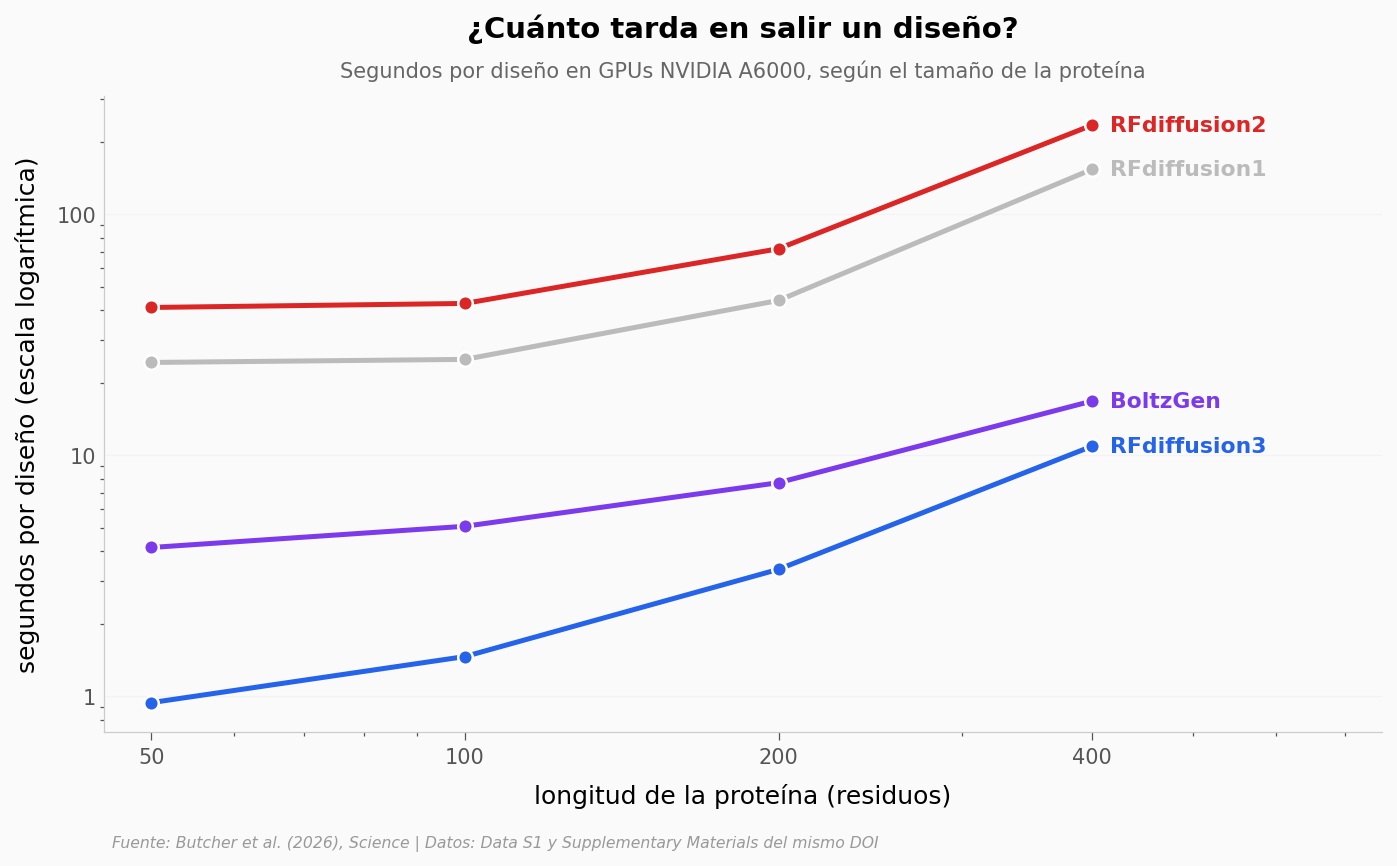

 50 residuos: RFD3   0,94 s  →  25,8× más rápido que RFD1, 43,6× que RFD2,  4,4× que BoltzGen
100 residuos: RFD3   1,46 s  →  17,1× más rápido que RFD1, 29,2× que RFD2,  3,5× que BoltzGen
200 residuos: RFD3   3,36 s  →  13,1× más rápido que RFD1, 21,4× que RFD2,  2,3× que BoltzGen
400 residuos: RFD3  10,90 s  →  14,1× más rápido que RFD1, 21,5× que RFD2,  1,5× que BoltzGen
  de 50 a 400 residuos, el tiempo de RFdiffusion3 se multiplica por 11,6
  de 50 a 400 residuos, el tiempo de RFdiffusion2 se multiplica por 5,7
  de 50 a 400 residuos, el tiempo de RFdiffusion1 se multiplica por 6,3
  de 50 a 400 residuos, el tiempo de BoltzGen se multiplica por 4,1


In [3]:
fig, ax = plt.subplots(figsize=(11, 5.5))
series = [('rfd3_s_por_diseno', 'RFdiffusion3', COLOR_DATOS),
          ('rfd2_s_por_diseno', 'RFdiffusion2', COLOR_ALERTA),
          ('rfd1_s_por_diseno', 'RFdiffusion1', COLOR_GRIS),
          ('boltzgen_s_por_diseno', 'BoltzGen', COLOR_VIOLETA)]
for col, nombre, color in series:
    ax.plot(vel.n_residuos, vel[col], color=color, lw=2.4, marker='o', ms=7,
            markeredgecolor='white', markeredgewidth=1.2)
    ax.text(vel.n_residuos.iloc[-1] * 1.04, vel[col].iloc[-1], nombre, color=color,
            fontsize=10.5, fontweight='bold', va='center')

ax.set_yscale('log')
ax.set_xscale('log')
ax.set_title('¿Cuánto tarda en salir un diseño?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, 'Segundos por diseño en GPUs NVIDIA A6000, según el tamaño de la proteína',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
ax.set_xlabel('longitud de la proteína (residuos)')
ax.set_ylabel('segundos por diseño (escala logarítmica)')
ax.set_xticks(vel.n_residuos)
ax.set_xticklabels([es(str(n)) for n in vel.n_residuos])
ax.set_xlim(45, 760)
ax.yaxis.set_major_formatter(COMA)
ax.grid(True, which='major', axis='y', alpha=0.25)
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/velocidad_inferencia.png', dpi=200, bbox_inches='tight')
plt.show()

for _, r in vel.iterrows():
    pr(f'{int(r.n_residuos):3d} residuos: RFD3 {r.rfd3_s_por_diseno:6.2f} s  →  '
       f'{r.rfd1_s_por_diseno/r.rfd3_s_por_diseno:4.1f}× más rápido que RFD1, '
       f'{r.rfd2_s_por_diseno/r.rfd3_s_por_diseno:4.1f}× que RFD2, '
       f'{r.boltzgen_s_por_diseno/r.rfd3_s_por_diseno:4.1f}× que BoltzGen')
for col, nombre, _ in series:
    pr(f'  de 50 a 400 residuos, el tiempo de {nombre} se multiplica por '
       f'{vel[col].iloc[-1]/vel[col].iloc[0]:.1f}')

A 50 residuos la diferencia es de otro orden: 0,94 segundos por diseño frente a 24,26 de RFD1 y 41,03 de RFD2 — 25,8× y 43,6×. A 400 residuos el margen se encoge a 14,1× y 21,5×, porque el tiempo de RFD3 crece más rápido con el tamaño (×11,6 de 50 a 400 residuos, frente a ×6,3 de RFD1). BoltzGen, el método externo más cercano, pasa de estar 4,4× por detrás a solo 1,5×.

Pero un benchmark es un benchmark. La pregunta que decide si todo esto sirve es otra: **¿sale del ordenador una enzima que funcione?**

El equipo lo probó con una fosfotriesterasa — una enzima que rompe enlaces fósforo-oxígeno, los de los pesticidas organofosforados y los agentes nerviosos. El sitio activo que pidieron es incómodo: una lisina **carbamilada** (una lisina con una molécula de CO₂ enganchada) coordinando dos iones metálicos. Encargaron 96 diseños, midieron, y cuatro de ellos — todos del mismo andamio — mostraron actividad. A ese andamio lo llamaron ZAPP-1.

La prueba de que la actividad viene del sitio activo **diseñado** y no de un accidente de la proteína es la siguiente: cambiar una a una las seis posiciones catalíticas por alanina, un aminoácido sin química que ofrecer.

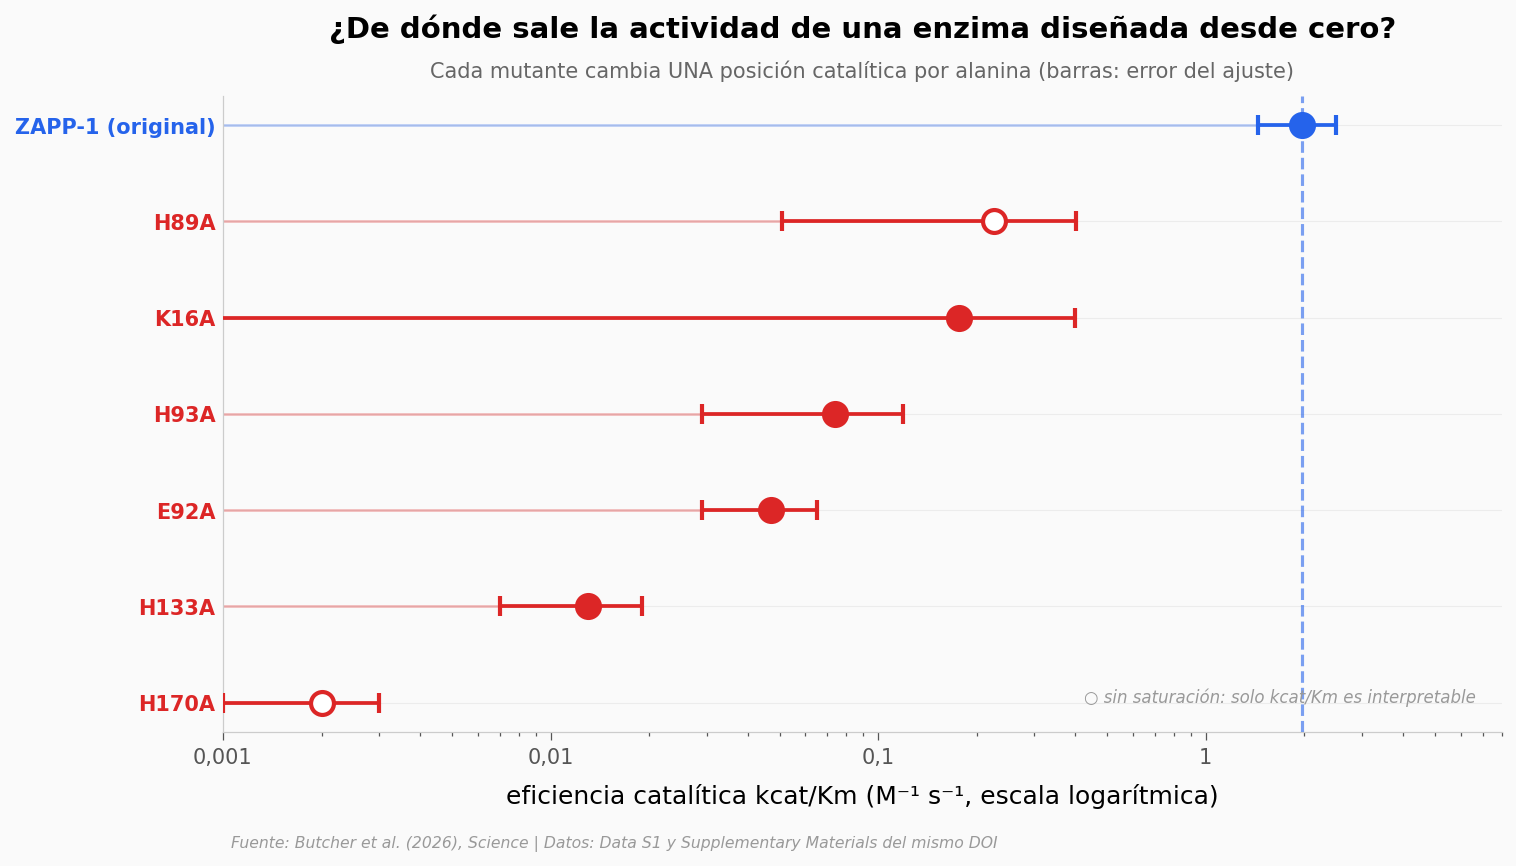

  H89A: kcat/Km   0,226 M⁻¹ s⁻¹  →     8,7× por debajo de ZAPP-1  (sin saturación)
  K16A: kcat/Km   0,176 M⁻¹ s⁻¹  →    11,2× por debajo de ZAPP-1
  H93A: kcat/Km   0,074 M⁻¹ s⁻¹  →    26,6× por debajo de ZAPP-1
  E92A: kcat/Km   0,047 M⁻¹ s⁻¹  →    41,9× por debajo de ZAPP-1
 H133A: kcat/Km   0,013 M⁻¹ s⁻¹  →   151,5× por debajo de ZAPP-1
 H170A: kcat/Km   0,002 M⁻¹ s⁻¹  →   985,0× por debajo de ZAPP-1  (sin saturación)
caída: mínima 8,7×, máxima 985,0×, mediana 34,3×
sin bicarbonato: kcat/Km 0,52 M⁻¹ s⁻¹ (3,8× menos que con 25 mM de NaHCO₃; kcat 11,4× menos)
proteasa de transtiretina TTRg10: kcat/Km  2946,0 M⁻¹ s⁻¹  (kcat 0,0266 s⁻¹, Km 9,0 µM)
proteasa de transtiretina TTRg11: kcat/Km  1100,3 M⁻¹ s⁻¹  (kcat 0,0718 s⁻¹, Km 65,3 µM)
proteasa de transtiretina TTRg4: kcat/Km   675,0 M⁻¹ s⁻¹  (kcat 0,0064 s⁻¹, Km 9,5 µM)


In [4]:
fig, ax = plt.subplots(figsize=(11, 5.5))

k = ko.copy()
k['etiqueta'] = k.variante.str.replace('ZAPP1_', '', regex=False).str.replace('ZAPP1', 'ZAPP-1 (original)', regex=False)
k = k.sort_values('kcat_km_M1s1')
y = np.arange(len(k))
colores = [COLOR_DATOS if v == 'ZAPP1' else COLOR_ALERTA for v in k.variante]

for yi, (_, r), c in zip(y, k.iterrows(), colores):
    ax.plot([1e-3, r.kcat_km_M1s1], [yi, yi], color=c, lw=1.2, alpha=0.35, zorder=2)
    relleno = c if r.saturacion_alcanzada == 'si' else 'white'
    ax.errorbar(r.kcat_km_M1s1, yi, xerr=r.kcat_km_std, fmt='o', ms=11, color=c,
                markerfacecolor=relleno, markeredgewidth=2, capsize=5, capthick=1.5, zorder=5)

parental = ko.loc[ko.variante == 'ZAPP1', 'kcat_km_M1s1'].iloc[0]
ax.axvline(parental, color=COLOR_DATOS, lw=1.5, ls='--', alpha=0.6, zorder=3)
ax.set_xscale('log')
ax.set_yticks(y)
ax.set_yticklabels(k.etiqueta, fontsize=10, fontweight='bold')
for tick, c in zip(ax.get_yticklabels(), colores):
    tick.set_color(c)
ax.set_title('¿De dónde sale la actividad de una enzima diseñada desde cero?',
             fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, 'Cada mutante cambia UNA posición catalítica por alanina (barras: error del ajuste)',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
ax.set_xlabel('eficiencia catalítica kcat/Km (M⁻¹ s⁻¹, escala logarítmica)')
ax.xaxis.set_major_formatter(COMA)
ax.set_xlim(1e-3, 8)
ax.text(0.98, 0.04, '○ sin saturación: solo kcat/Km es interpretable', transform=ax.transAxes,
        fontsize=8, color='#999999', ha='right', va='bottom', style='italic')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/zapp1_knockouts.png', dpi=200, bbox_inches='tight')
plt.show()

mut = ko[ko.variante != 'ZAPP1'].copy()
mut['caida'] = parental / mut.kcat_km_M1s1
for _, r in mut.sort_values('caida').iterrows():
    sat = '' if r.saturacion_alcanzada == 'si' else '  (sin saturación)'
    pr(f'{r.variante.replace("ZAPP1_", ""):>6}: kcat/Km {r.kcat_km_M1s1:7.3f} M⁻¹ s⁻¹  →  '
       f'{r.caida:6.1f}× por debajo de ZAPP-1{sat}')
pr(f'caída: mínima {mut.caida.min():.1f}×, máxima {mut.caida.max():.1f}×, mediana {mut.caida.median():.1f}×')
pr(f'sin bicarbonato: kcat/Km {fit.kcat_km_M1s1.iloc[1]:.2f} M⁻¹ s⁻¹ '
   f'({fit.kcat_km_M1s1.iloc[0]/fit.kcat_km_M1s1.iloc[1]:.1f}× menos que con 25 mM de NaHCO₃; '
   f'kcat {fit.kcat_s1.iloc[0]/fit.kcat_s1.iloc[1]:.1f}× menos)')
for _, r in prot.sort_values('kcat_km_M1s1', ascending=False).iterrows():
    pr(f'proteasa de transtiretina TTRg{r.variante[1:]}: kcat/Km {r.kcat_km_M1s1:7.1f} M⁻¹ s⁻¹  '
       f'(kcat {r.kcat_s1:.4f} s⁻¹, Km {r.Km_uM:.1f} µM)')

Las seis alaninas bajan la eficiencia entre 8,7× y 985× (mediana 34×): la química está donde el diseño decía que estaría. Quitar el bicarbonato del tampón — y con él la posibilidad de carbamilar la lisina — cuesta otro factor 3,8× en eficiencia y 11,4× en velocidad de recambio. En paralelo, las tres proteasas de zinc contra la transtiretina llegan a 675, 1.100 y 2.946 M⁻¹ s⁻¹: la mejor de las tres no es la de mayor kcat (ese es TTRg11, 0,072 s⁻¹) sino la que agarra mejor el sustrato (TTRg10, Km de 9 µM).

Queda el número que pone todo lo anterior en escala. Para elegir qué 96 proteínas encargar, hay que generar muchas más y quedarse con las mejores. Entonces: **de 16.000 diseños por teozima, ¿cuántos colocan el sitio activo donde debe estar?**

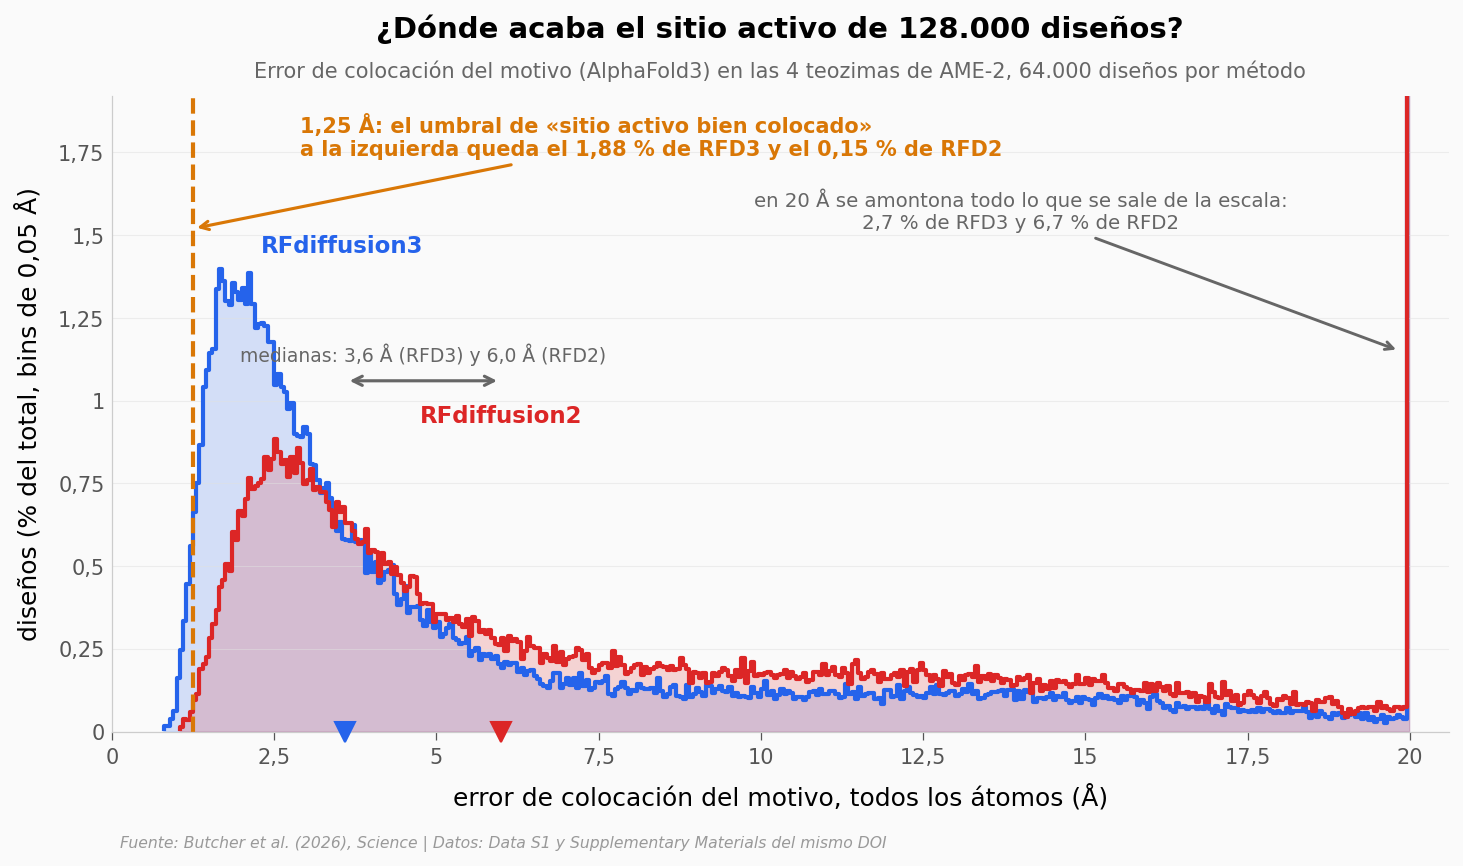

RFdiffusion3   n = 64.000 diseños | bajo 1,25 Å: 1,883 % | bajo 2 Å: 19,27 % | mediana 3,60 Å | en el bin de 20 Å o más: 2,7 %
RFdiffusion2   n = 64.000 diseños | bajo 1,25 Å: 0,148 % | bajo 2 Å: 5,68 % | mediana 6,00 Å | en el bin de 20 Å o más: 6,7 %
ventaja de RFD3 en la fracción bajo 1,25 Å: 12,7×
  aldolasa          RFD3  1,98 %  RFD2  0,41 %  →  4,8×
  descarboxilasa    RFD3  0,10 %  RFD2  0,01 %  →  8,0×
  glicosidasa       RFD3  1,41 %  RFD2  0,00 %  →  RFD2 no logró ninguno
  fosfotriesterasa  RFD3  4,04 %  RFD2  0,17 %  →  23,9×


In [5]:
fig, ax = plt.subplots(figsize=(11.5, 5.5))

estilos = {'rfd3': ('RFdiffusion3', COLOR_DATOS), 'rfd2': ('RFdiffusion2', COLOR_ALERTA)}
resumen = {}
for m, (nombre, color) in estilos.items():
    s = hist[hist.metodo == m].groupby(['bin_inf_A', 'bin_sup_A'], as_index=False).n_disenos.sum()
    s = s.sort_values('bin_inf_A')
    n_tot = s.n_disenos.sum()
    pct = (s.n_disenos / n_tot * 100).values
    ax.step(s.bin_sup_A, pct, where='pre', color=color, lw=2.0)
    ax.fill_between(s.bin_sup_A, pct, step='pre', color=color, alpha=0.18)
    acum = s.n_disenos.cumsum()
    bajo = s[s.bin_sup_A <= UMBRAL_A].n_disenos.sum()
    mediana = float(s.bin_sup_A.values[np.searchsorted(acum.values, n_tot / 2)])
    # el último bin (19,95–20 Å) acumula todo lo que se sale de la escala original
    moda_x = float(s.bin_sup_A.values[:-1][pct[:-1].argmax()])
    resumen[m] = {'n': int(n_tot), 'pct': 100 * bajo / n_tot, 'mediana': mediana,
                  'pct2': 100 * s[s.bin_sup_A <= 2.0].n_disenos.sum() / n_tot,
                  'tope': float(pct[-1]), 'pico': float(pct[:-1].max())}
    ax.plot([mediana], [0.0], marker='v', ms=10, color=color, clip_on=False, zorder=8)
    ax.text(moda_x + (0.6 if m == 'rfd3' else 2.2), resumen[m]['pico'] + 0.05, nombre,
            color=color, fontsize=11, fontweight='bold', ha='left')

ax.axvline(UMBRAL_A, color=COLOR_REFERENCIA, lw=2.0, ls='--')
pct3 = es(f'{resumen["rfd3"]["pct"]:.2f}')
pct2 = es(f'{resumen["rfd2"]["pct"]:.2f}')
nota = (es(f'{UMBRAL_A:.2f}') + ' Å: el umbral de «sitio activo bien colocado»\n'
        + 'a la izquierda queda el ' + pct3 + ' % de RFD3 y el ' + pct2 + ' % de RFD2')
ax.annotate(nota, xy=(UMBRAL_A, 1.52), xytext=(2.9, 1.74), fontsize=10, fontweight='bold',
            color=COLOR_REFERENCIA,
            arrowprops=dict(arrowstyle='->', color=COLOR_REFERENCIA, lw=1.5))
m3, m2 = resumen['rfd3']['mediana'], resumen['rfd2']['mediana']
ax.annotate('', xy=(m3, 1.06), xytext=(m2, 1.06),
            arrowprops=dict(arrowstyle='<->', color='#666666', lw=1.5))
etiq_med = ('medianas: ' + es(f'{m3:.1f}') + ' Å (RFD3) y ' + es(f'{m2:.1f}') + ' Å (RFD2)')
ax.text((m3 + m2) / 2, 1.12, etiq_med, fontsize=9, color='#666666', ha='center')

# el histograma del paper mete en el último bin todo diseño con error ≥ 20 Å
tope = ('en 20 Å se amontona todo lo que se sale de la escala:\n'
        + es(f'{resumen["rfd3"]["tope"]:.1f}') + ' % de RFD3 y '
        + es(f'{resumen["rfd2"]["tope"]:.1f}') + ' % de RFD2')
ax.annotate(tope, xy=(19.85, 1.15), xytext=(14.0, 1.52), fontsize=9.5, color='#666666',
            ha='center', arrowprops=dict(arrowstyle='->', color='#666666', lw=1.4))

ax.set_title('¿Dónde acaba el sitio activo de 128.000 diseños?', fontsize=14, fontweight='bold', pad=28)
ax.set_xlim(0, 20.6)
ax.set_ylim(0, 1.92)
ax.text(0.5, 1.03, 'Error de colocación del motivo (AlphaFold3) en las 4 teozimas de AME-2, '
        '64.000 diseños por método',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
ax.set_xlabel('error de colocación del motivo, todos los átomos (Å)')
ax.set_ylabel('diseños (% del total, bins de 0,05 Å)')
ax.xaxis.set_major_formatter(COMA)
ax.yaxis.set_major_formatter(COMA)
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/ame2_distribucion_rmsd.png', dpi=200, bbox_inches='tight')
plt.show()

for m, (nombre, _) in estilos.items():
    r = resumen[m]
    pr(f'{nombre:<14} n = {r["n"]:_} diseños | bajo {UMBRAL_A} Å: {r["pct"]:.3f} % | '
       f'bajo 2 Å: {r["pct2"]:.2f} % | mediana {r["mediana"]:.2f} Å | '
       f'en el bin de 20 Å o más: {r["tope"]:.1f} %')
pr(f'ventaja de RFD3 en la fracción bajo {UMBRAL_A} Å: '
   f'{resumen["rfd3"]["pct"]/resumen["rfd2"]["pct"]:.1f}×')
tabla = ame2.pivot(index='tarea', columns='metodo', values='pct_motif_rmsd_lt_1p25')
for tarea, r in tabla.iterrows():
    ratio = f'{r.rfd3/r.rfd2:.1f}×' if r.rfd2 > 0 else 'RFD2 no logró ninguno'
    pr(f'  {NOMBRES[tarea]:<17} RFD3 {r.rfd3:5.2f} %  RFD2 {r.rfd2:5.2f} %  →  {ratio}')

### Lo que los datos soportan

| Afirmación | ¿Soportada? | Detalle |
|------------|-------------|---------|
| RFD3 acierta más que RFD2 en el benchmark AME | ✅ | 37,7 % frente a 23,5 % de media; gana en 37 de 41 tareas (Wilcoxon pareado p = 1,7×10⁻⁷, d pareado = 1,28). Las tasas de RFD1 y RFD2 son las publicadas por los autores, no una reevaluación nuestra |
| La ventaja crece con el tamaño del motivo | ✅ | 1,50× con 1–4 islas de residuos (n = 29 tareas) y 3,67× con 5–7 (n = 12). Spearman ρ = −0,77 (RFD3) y −0,85 (RFD2) entre islas y acierto. El paper lo enuncia como «más de cuatro residuos catalíticos»; la columna publicada cuenta islas de residuos contiguos, no residuos |
| RFD3 genera diseños más rápido | ✅ | 25,8× más rápido que RFD1 y 43,6× que RFD2 a 50 residuos; 14,1× y 21,5× a 400. Son tiempos medidos por los autores en GPUs A6000 (Table S8), no recronometrados aquí |
| La ventaja en velocidad se mantiene al crecer la proteína | ⚠️ | Se estrecha: el tiempo de RFD3 se multiplica por 11,6 de 50 a 400 residuos y el de RFD1 por 6,3. Frente a BoltzGen cae de 4,4× a 1,5× |
| En AME-2, RFD3 coloca el motivo bajo 1,25 Å mucho más a menudo | ✅ | 1,88 % frente a 0,15 % sobre 64.000 diseños por método (12,7×); medianas de error 3,60 Å y 6,00 Å. En la glicosidasa RFD2 no logró ninguno de 16.000. Por el otro extremo, el 6,7 % de los diseños de RFD2 y el 2,7 % de los de RFD3 acaban en 20 Å o más. Criterio distinto al de AME-1 (AlphaFold3 < 1,25 Å aquí; Chai-1 < 1,5 Å y sin choques allí): los dos porcentajes no se mezclan |
| ZAPP-1 es una fosfotriesterasa activa y su actividad viene del sitio activo diseñado | ✅ | kcat/Km = 1,97 ± 0,53 M⁻¹ s⁻¹ (R² del ajuste = 0,990); las seis alaninas bajan la eficiencia entre 8,7× y 985× (mediana 34×). H89A y H170A no alcanzan saturación: de ellas solo kcat/Km es interpretable, y en H89A la hoja del panel da 0,226 donde la Table S3 da 0,16 ± 0,02 (8,7× frente a 12,3×) |
| El bicarbonato hace falta para la catálisis | ✅ | Sin NaHCO₃, kcat/Km cae 3,8× y kcat 11,4×. Es coherente con la lisina carbamilada del diseño, aunque el experimento por sí solo no demuestra la carbamilación |
| Las proteasas de zinc contra transtiretina funcionan | ✅ | kcat/Km de 675, 1.100 y 2.946 M⁻¹ s⁻¹, dentro de lo que reporta la Table S4 (700 ± 200, 1.100 ± 300, 2.900 ± 500) |
| Catalizadores activos «a la primera», en campañas de 96 construcciones | ⚠️ | La primera campaña fue de 96 diseños en 6 andamios y avanzaron 4, todos del mismo andamio. La segunda (192 diseños, 11 andamios) usó el análisis de ZAPP-1 para derivar su teozima: no es una campaña ciega independiente. Las 12 enzimas con cinética completa las eligieron los autores del cribado, así que su rango de eficiencia (0,34–4,01 M⁻¹ s⁻¹) no es la distribución de los diseños encargados |

> **Limitaciones.** (1) Todas las comparaciones entre métodos usan números publicados por los propios autores: aquí no se reentrenó ni se volvió a correr ningún modelo. (2) AME-1 y AME-2 miden el acierto con herramientas y umbrales distintos y no son intercambiables. (3) El histograma de AME-2 viene de nuestra agregación en bins de 0,05 Å de los 128.000 diseños originales; es exacta en el umbral de 1,25 Å porque cae en un borde de bin, y las medianas que imprime tienen la resolución del bin. El último bin (20 Å) acumula todo diseño con un error mayor, así que la cola derecha está recortada y no se puede leer su forma. (4) Las aceleraciones frente a la reacción sin enzima que da el paper (unas 3×10⁵ veces para ZAPP-1) usan tasas no catalizadas tomadas de la literatura, a veces a otra temperatura que el ensayo: son estimaciones de orden de magnitud. (5) Nada de esto se ha probado en un organismo: son proteínas expresadas en bacteria y medidas en el tubo.

### Ahora tú

1. **¿Y si el umbral fuera más blando?** El paper corta en 1,25 Å, pero la frontera de lo útil depende de la enzima. ¿Cómo cambia la ventaja de RFD3 si pides 2 Å o 3 Å? *Pista:* cambia `UMBRAL_A` en la celda de configuración y vuelve a ejecutar, o mira el barrido de la celda siguiente.
2. **¿Qué teozima le cuesta más a cada método?** Las cuatro (aldolasa, descarboxilasa, glicosidasa, fosfotriesterasa) no son igual de difíciles, y el orden no es el mismo para RFD2 que para RFD3. *Pista:* `ame2.pivot(index='tarea', columns='metodo', values='mediana_motif_rmsd_A')`.
3. **¿Cuántas tareas del benchmark AME le quedan por resolver?** Prueba a contar cuántas tareas siguen por debajo del 10 % de acierto con RFD3 y cuántas islas tienen. *Pista:* `ame[ame.rfd3_pass_rate < 0.10][['tarea', 'islas_residuos', 'rfd3_pass_rate']]`.

In [6]:
# --- EXPERIMENTA AQUÍ ---
# ¿La ventaja de RFD3 depende de dónde pongas el umbral de «bien colocado»?
# Barremos el umbral y recomputamos la fracción de diseños que lo pasan, para cada método.

pr(f'{"umbral (Å)":>11} {"RFD3":>9} {"RFD2":>9} {"ventaja":>9}')
for u in [1.0, 1.25, 1.5, 2.0, 3.0, 4.0, 6.0]:
    fila = {}
    for m in ['rfd3', 'rfd2']:
        s = hist[hist.metodo == m]
        fila[m] = 100 * s[s.bin_sup_A <= u].n_disenos.sum() / s.n_disenos.sum()
    ventaja = f'{fila["rfd3"]/fila["rfd2"]:.1f}×' if fila['rfd2'] > 0 else '—'
    pr(f'{u:>11} {fila["rfd3"]:8.2f} % {fila["rfd2"]:8.2f} % {ventaja:>9}')

# Y la misma pregunta en una sola teozima (cambia TEOZIMA arriba):
s = hist[hist.tarea == TEOZIMA]
pr(f'\nSolo la teozima de {NOMBRES[TEOZIMA]}:')
for m in ['rfd3', 'rfd2']:
    sm = s[s.metodo == m]
    bajo = 100 * sm[sm.bin_sup_A <= UMBRAL_A].n_disenos.sum() / sm.n_disenos.sum()
    pr(f'  {m.upper()}: {bajo:.2f} % de {sm.n_disenos.sum():_} diseños bajo {UMBRAL_A} Å')

 umbral (Å)      RFD3      RFD2   ventaja
        1,0     0,14 %     0,00 %         —
       1,25     1,88 %     0,15 %     12,7×
        1,5     6,30 %     0,97 %      6,5×
        2,0    19,27 %     5,68 %      3,4×
        3,0    41,61 %    21,39 %      1,9×
        4,0    54,79 %    34,61 %      1,6×
        6,0    68,18 %    50,11 %      1,4×

Solo la teozima de fosfotriesterasa:
  RFD3: 4,04 % de 16.000 diseños bajo 1,25 Å
  RFD2: 0,17 % de 16.000 diseños bajo 1,25 Å


## Fuentes

**Paper**: [Atomic functional site scaffolding in biopolymers with RFdiffusion3](https://doi.org/10.1126/science.aeh2982)  
*Science, 2026-11-26*

**Supplementary Material**: [Supplementary Materials for 'Atomic functional site scaffolding in biopolymers with RFdiffusion3' (Materials and Methods, Figs. S1-S19, Tables S1-S15)](https://www.science.org/doi/suppl/10.1126/science.aeh2982/suppl_file/science.aeh2982_sm.pdf)  
*Science, 2026-11-26*

**Source Data**: [Data S1: Source Data for panels in the main text and supplemental information (RFdiffusion3)](https://www.science.org/doi/suppl/10.1126/science.aeh2982/suppl_file/science.aeh2982_data_s1.zip)  
*Science, 2026-11-26*

*El paper no deposita datos en ningún repositorio externo: todos los números salen del Data S1 y del material suplementario publicados con el mismo DOI.*

*28 afirmaciones verificadas contra estas fuentes*

---

**Datos:** Data S1 y Supplementary Materials publicados con el mismo DOI que el artículo. Los CSV de `datos/` son extractos de esas hojas; el histograma de AME-2 es una agregación en bins de 0,05 Å de los 128.000 diseños originales.

**Licencia:** el código de este notebook, MIT. Los datos, los términos del editor (Science / AAAS).

**Repo:** [Ciencia-a-Mordiscos/lab](https://github.com/Ciencia-a-Mordiscos/lab) · parte de [Ciencia a Mordiscos](https://cienciaamordiscos.com)